#import librararies

In [2]:
import numpy as np  
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import os
from sklearn.base import clone
from collections import Counter
from sklearn.model_selection import train_test_split , GridSearchCV , StratifiedKFold ,cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, accuracy_score , confusion_matrix , 
                             ConfusionMatrixDisplay , roc_curve, auc , roc_auc_score, 
                             RocCurveDisplay , PrecisionRecallDisplay)
from sklearn.ensemble import RandomForestClassifier , VotingClassifier
from xgboost import XGBClassifier 
from sklearn.preprocessing import StandardScaler , MinMaxScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

#Loading dataset's images

In [3]:
image_path = "dataset/normal/" + os.listdir("dataset/normal")[0]
image = cv2.imread(image_path)
print(f"Image shape: {image.shape}")

dataset_path = "dataset"
sizes = []
for class_name in ["normal", "Oral Cancer photos"]:
    class_path = os.path.join(dataset_path, class_name)
    for filename in os.listdir(class_path):
        image_path = os.path.join(class_path, filename)
        image = cv2.imread(image_path)
        if image is not None:
            height, width = image.shape[:2]
            sizes.append((width, height))

print("Total valid images:", len(sizes))
size_counts = Counter(sizes)
print("\nNumber of different image sizes:", len(size_counts))
print("\nMost common sizes:")
for size, count in size_counts.most_common(20):
    print(size, "-->", count)

Image shape: (126, 144, 3)
Total valid images: 1238

Number of different image sizes: 932

Most common sizes:
(280, 205) --> 39
(960, 1280) --> 30
(468, 1040) --> 18
(720, 1280) --> 13
(275, 183) --> 12
(1800, 4000) --> 10
(500, 333) --> 10
(1100, 618) --> 9
(225, 225) --> 7
(500, 375) --> 6
(1280, 720) --> 5
(274, 184) --> 5
(1280, 1280) --> 5
(1280, 960) --> 5
(620, 415) --> 5
(1105, 950) --> 5
(1280, 719) --> 5
(720, 415) --> 4
(600, 400) --> 4
(3024, 4032) --> 4


#showing and Resizing Images

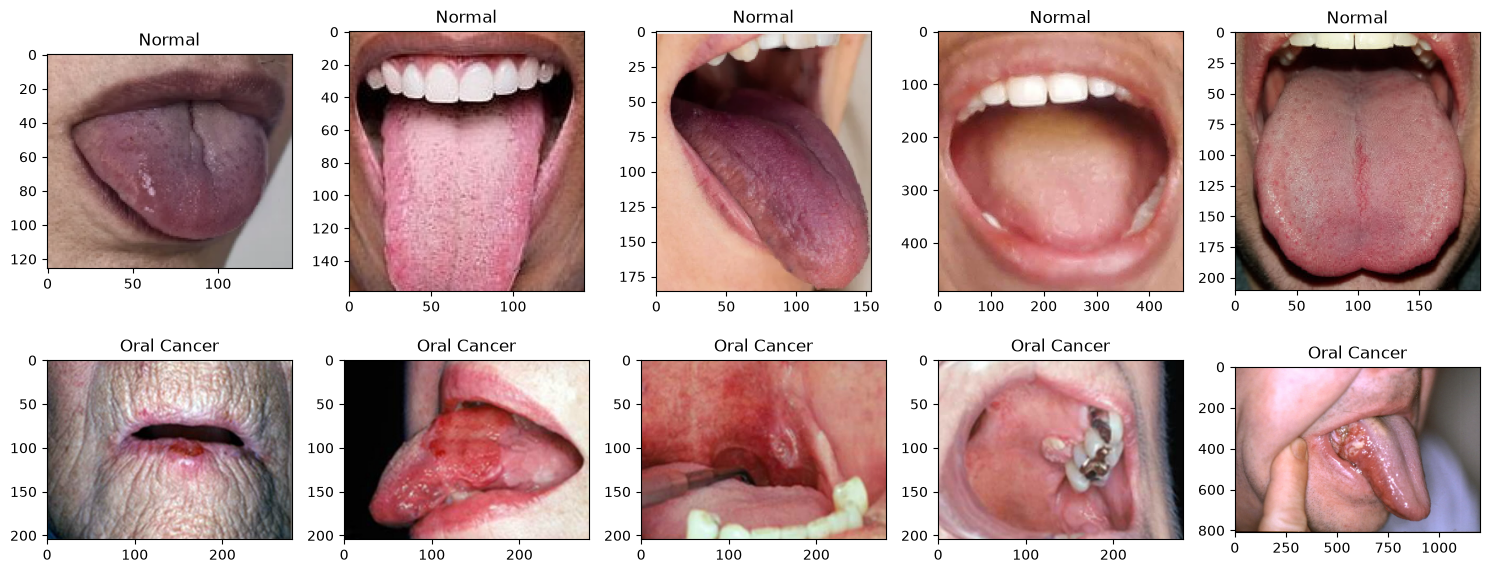

In [4]:

dataset_path = "dataset"

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Normal
normal_path = os.path.join(dataset_path, "normal")
normal_files = os.listdir(normal_path)

for i in range(5):
    image_path = os.path.join(normal_path, normal_files[i])
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[0, i].imshow(image)
    axes[0, i].set_title("Normal")


# Oral Cancer
cancer_path = os.path.join(dataset_path, "Oral Cancer photos")
cancer_files = os.listdir(cancer_path)

for i in range(5):
    image_path = os.path.join(cancer_path, cancer_files[i])
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[1, i].imshow(image)
    axes[1, i].set_title("Oral Cancer")


plt.tight_layout()
plt.show()

#Resizing images

In [5]:

for class_name in ["normal", "Oral Cancer photos"]:
    input_folder = "dataset/" + class_name
    output_folder = "dataset_128/" + class_name
    os.makedirs(output_folder, exist_ok=True)
    for filename in os.listdir(input_folder):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        image_path = input_folder + "/" + filename
        image = cv2.imread(image_path)
        if image is None:
            continue
    
        rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        resized = cv2.resize(image, (128, 128))
        output_path = output_folder + "/" + filename
        cv2.imwrite(output_path, resized)


#Convert to Gray

In [6]:

for class_name in ["normal", "Oral Cancer photos"]:
    input_folder = "dataset_128/" + class_name
    output_folder = "dataset_gray/" + class_name
    os.makedirs(output_folder, exist_ok=True)
    for filename in os.listdir(input_folder):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        image_path = input_folder + "/" + filename
        image = cv2.imread(image_path)
        if image is None:
            continue
        # BGR to Gray
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        output_path = output_folder + "/" + filename
        cv2.imwrite(output_path, gray)


#Edge Detection with HOG 

In [7]:
hog = cv2.HOGDescriptor(
    (128, 128),
    (16, 16),
    (8, 8),
    (8, 8),
    9
)

X = []
y = []

for class_name, label in [("normal", 0), ("Oral Cancer photos", 1)]:
    folder = "dataset_gray/" + class_name
    for filename in os.listdir(folder):
        image_path = folder + "/" + filename
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        if image is None:
            continue

        
        features = hog.compute(image)
        X.append(features.flatten())
        y.append(label)

X = np.array(X)
y = np.array(y)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X: {X}")
print(f"y: {y}")

X shape: (1233, 8100)
y shape: (1233,)
X: [[0.0412041  0.053201   0.08537277 ... 0.02557928 0.00854817 0.25287938]
 [0.13613783 0.29866236 0.30928993 ... 0.03287809 0.06582852 0.15136759]
 [0.173086   0.37155986 0.16484533 ... 0.0101348  0.01438636 0.11519618]
 ...
 [0.19659379 0.14363803 0.16457944 ... 0.0169657  0.03630967 0.06604816]
 [0.05561455 0.05471455 0.11329596 ... 0.02759249 0.09891145 0.26213065]
 [0.17422865 0.13745657 0.06212024 ... 0.10256297 0.03436444 0.11096244]]
y: [0 0 0 ... 1 1 1]


#Train and Test split

In [8]:
X_Train , X_Test , y_Train , y_Test= train_test_split(X , 
                                                      y,
                                                      test_size=0.2,
                                                      random_state= 42,
                                                      stratify= y )
print(f"X_Traine : {X_Train.shape}")
print(f"X_Test: {X_Test.shape}")
print(f"y_Train: {y_Train.shape}")
print(f"y_Test: {y_Test.shape}")

#X_Train1 , X_val , y_Train1 , y_val= train_test_split(X_Train,
#                                                      y_Train, 
#                                                      test_size=0.2,
#                                                      random_state= 42,
#                                                      stratify= y_Train)

#print(f"X_Train1 : {X_Train1.shape}")
#print(f"X_val: {X_val.shape}")
#print(f"y_Train1: {y_Train1.shape}")
#print(f"y_val: {y_val.shape}")


X_Traine : (986, 8100)
X_Test: (247, 8100)
y_Train: (986,)
y_Test: (247,)


#Cross validation

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#Tree Decision algorithem

In [10]:
clf_tree= DecisionTreeClassifier(class_weight="balanced", splitter= "best", random_state= 42)

pipe_tree=Pipeline([("model" , clf_tree)])

param = {
    "model__criterion":["gini", "entropy"],
    "model__max_depth": [2 , 5, 10],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2, 5]
}


grid = GridSearchCV(
    pipe_tree,
    param,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=10
)

grid.fit(X_Train, y_Train)

best_param= grid.best_params_
best_score= grid.best_score_
best_tree = grid.best_estimator_
tree_model = best_tree.named_steps["model"]

print(f"Best Parameters:{best_param}")
print(f"Best CV Accuracy: {best_score}")
print(f"Best Tree: {best_tree}")
print(f"tree model: {tree_model}")

y_pred = grid.predict(X_Test)


classification_report_tree = classification_report(y_Test, y_pred)
test_accuracy = accuracy_score(y_Test, y_pred)
cm_tree = confusion_matrix(y_Test, y_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Classification Report - Test:\n{classification_report_tree}")
print(f"confusion_matrix: {cm_tree}")


Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Parameters:{'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}
Best CV Accuracy: 0.7272009434445982
Best Tree: Pipeline(steps=[('model',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                                        min_samples_split=5,
                                        random_state=42))])
tree model: DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                       min_samples_split=5, random_state=42)
Test Accuracy: 0.6923
Classification Report - Test:
              precision    recall  f1-score   support

           0       0.68      0.59      0.63       110
           1       0.70      0.77      0.74       137

    accuracy                           0.69       247
   macro avg       0.69      0.68      0.68       247
weighted avg       0.69      0.69      0.69       247

confusion_matrix: [[ 65

##Decision Tree structure

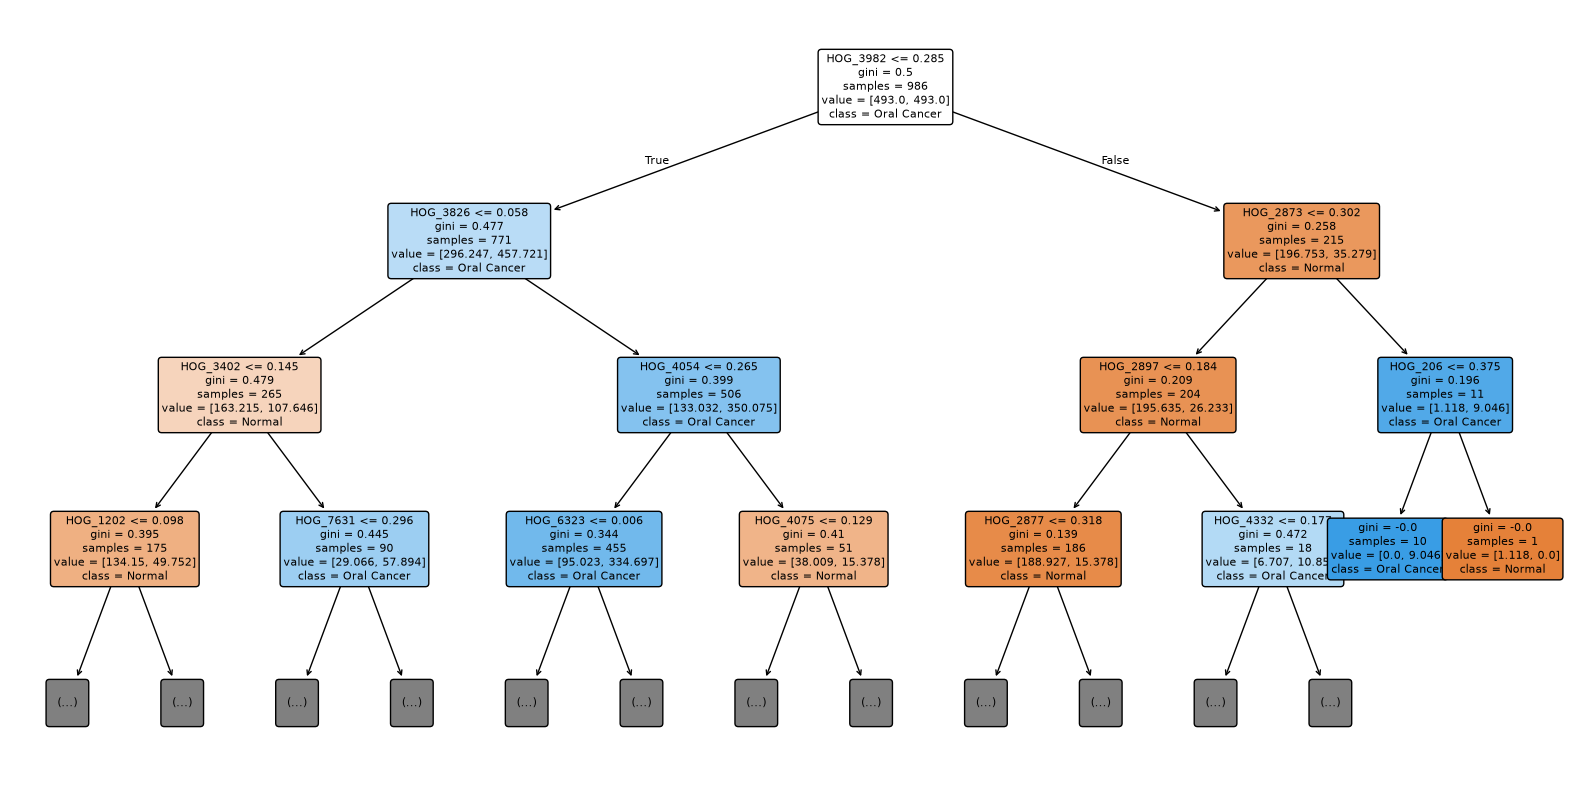

In [11]:
plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    max_depth=3,
    filled=True,
    feature_names=[f"HOG_{i}" for i in range(X_Train.shape[1])],
    class_names=["Normal", "Oral Cancer"],
    rounded=True,
    fontsize=8
)
plt.show()

##Confusion matrix

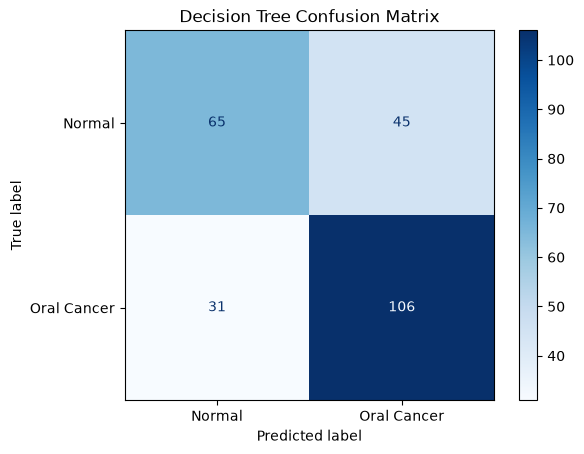

In [12]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tree,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree Confusion Matrix")
plt.show()
plt.show()

##feature importance

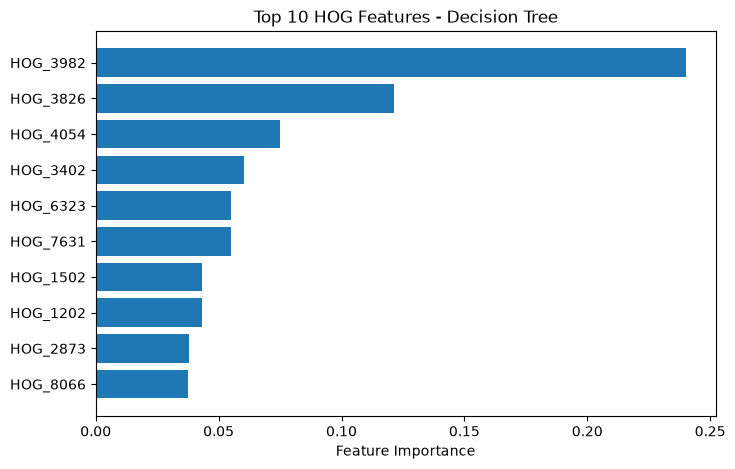

In [13]:
tree_model = grid.best_estimator_.named_steps["model"]
importance = tree_model.feature_importances_

indices = np.argsort(importance)[-10:]

plt.figure(figsize=(8, 5))

plt.barh(
    range(10),
    importance[indices]
)
plt.yticks(
    range(10),
    [f"HOG_{i}" for i in indices]
)

plt.xlabel("Feature Importance")
plt.title("Top 10 HOG Features - Decision Tree")
plt.show()

##ROC curve

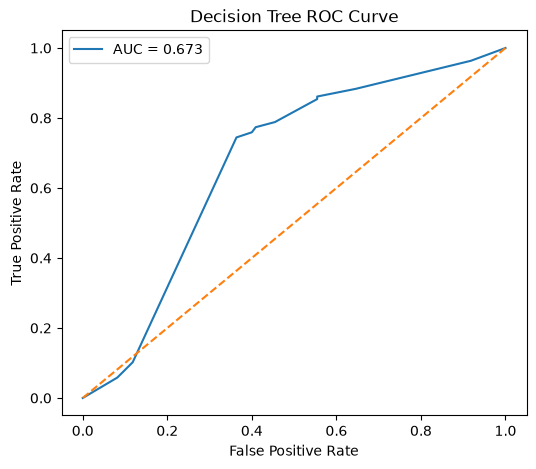

In [14]:
tree_model = grid.best_estimator_.named_steps["model"]

y_test_prob = tree_model.predict_proba(X_Test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_Test, y_test_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")
plt.legend()

plt.show()

#Random Forest Classifire Algorithem

In [15]:
clf_random_forest= RandomForestClassifier(class_weight="balanced" , random_state=42)
pipeline_random_forest=Pipeline([("model", clf_random_forest)])

param_random_forest = {
    "model__n_estimators":[100, 200 , 300],
    "model__criterion":["gini", "entropy"],
    "model__max_depth": [2 , 5, 10],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2, 5]
}
grid_random_forest= GridSearchCV(pipeline_random_forest, 
                                 param_random_forest ,
                                 cv=cv , 
                                 scoring = "accuracy" , 
                                 n_jobs = -1,
                                 verbose=10)


grid_random_forest.fit(X_Train, y_Train)
y_pred_test= grid_random_forest.predict(X_Test)

best_estimator = grid_random_forest.best_estimator_
best_param = grid_random_forest.best_params_
best_score = grid_random_forest.best_score_
print(f"Best estimators: {best_estimator}")
print(f"Best param: {best_param}")
print(f"Best score: {best_score}")

acc_score=accuracy_score(y_Test, y_pred_test)
clf_report=classification_report(y_Test, y_pred_test,  target_names=["Normal", "Oral Cancer"])
cm_randomforest = confusion_matrix(y_Test, y_pred_test)


print(f"Random Forest Test Accuracy: {acc_score:.4f}")
print(f"Classification Report: {clf_report}")
print(f"confusion_matrix: {cm_randomforest}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best estimators: Pipeline(steps=[('model',
                 RandomForestClassifier(class_weight='balanced',
                                        criterion='entropy', max_depth=10,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_estimators=300, random_state=42))])
Best param: {'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 300}
Best score: 0.8286314925908835
Random Forest Test Accuracy: 0.8259
Classification Report:               precision    recall  f1-score   support

      Normal       0.84      0.75      0.79       110
 Oral Cancer       0.82      0.88      0.85       137

    accuracy                           0.83       247
   macro avg       0.83      0.82      0.82       247
weighted avg       0.83      0.83      0.82       247

confusion_matrix: [[ 

##Confusion matrix for RandomForest

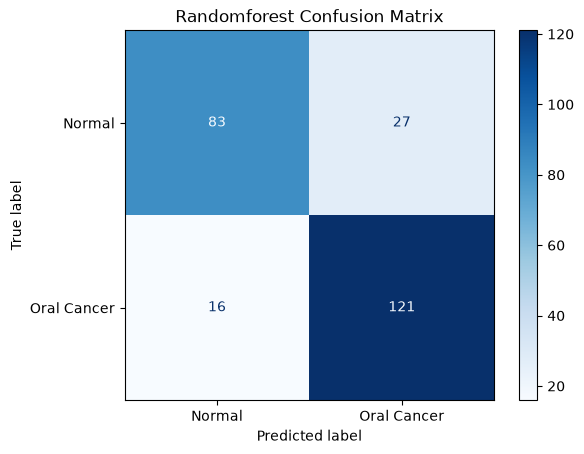

In [16]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_randomforest,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Randomforest Confusion Matrix")
plt.show()
plt.show()

##Importance feature for RandomForest

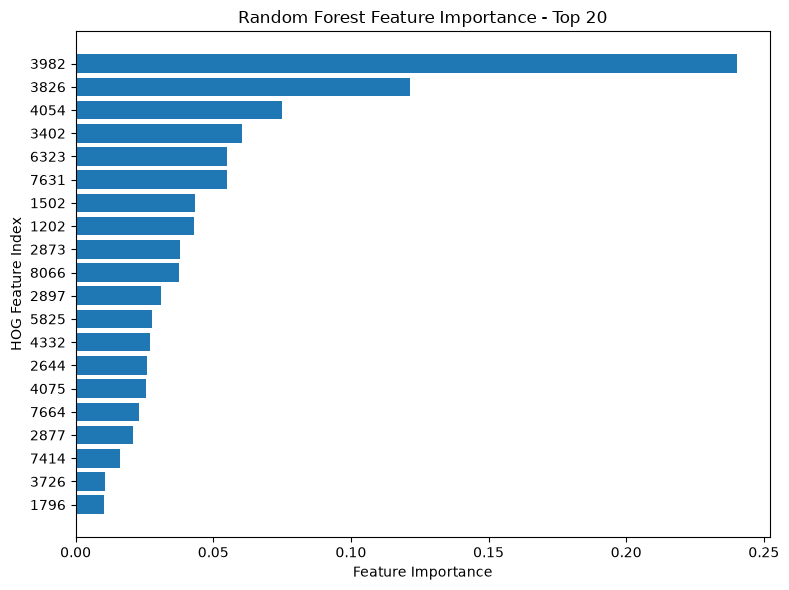

In [17]:
RandomForest_model = grid.best_estimator_.named_steps["model"]
importances = RandomForest_model.feature_importances_

indices = np.argsort(importances)[-20:]

plt.figure(figsize=(8, 6))

plt.barh(
    range(len(indices)),
    importances[indices]
)

plt.yticks(
    range(len(indices)),
    indices
)

plt.xlabel("Feature Importance")
plt.ylabel("HOG Feature Index")
plt.title("Random Forest Feature Importance - Top 20")

plt.tight_layout()
plt.show()

##ROC curve for RandomForest

Random Forest ROC-AUC: 0.8699


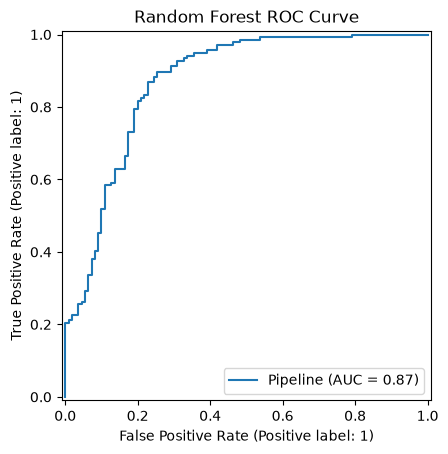

In [18]:
best_rf = grid_random_forest.best_estimator_

y_score_rf = best_rf.predict_proba(X_Test)[:, 1]

auc_rf = roc_auc_score(y_Test, y_score_rf)
print(f"Random Forest ROC-AUC: {auc_rf:.4f}")

RocCurveDisplay.from_estimator(
    grid_random_forest.best_estimator_,
    X_Test,
    y_Test
)

plt.title("Random Forest ROC Curve")
plt.show()

##PrecisionRecall for RandomForest

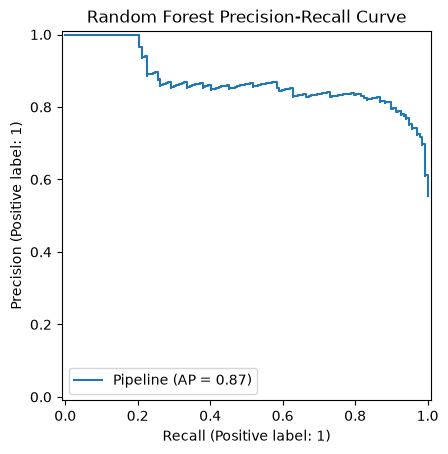

In [19]:
PrecisionRecallDisplay.from_estimator(
    grid_random_forest.best_estimator_,
    X_Test,
    y_Test
)

plt.title("Random Forest Precision-Recall Curve")
plt.show()

##showing one of trees in RandomForest

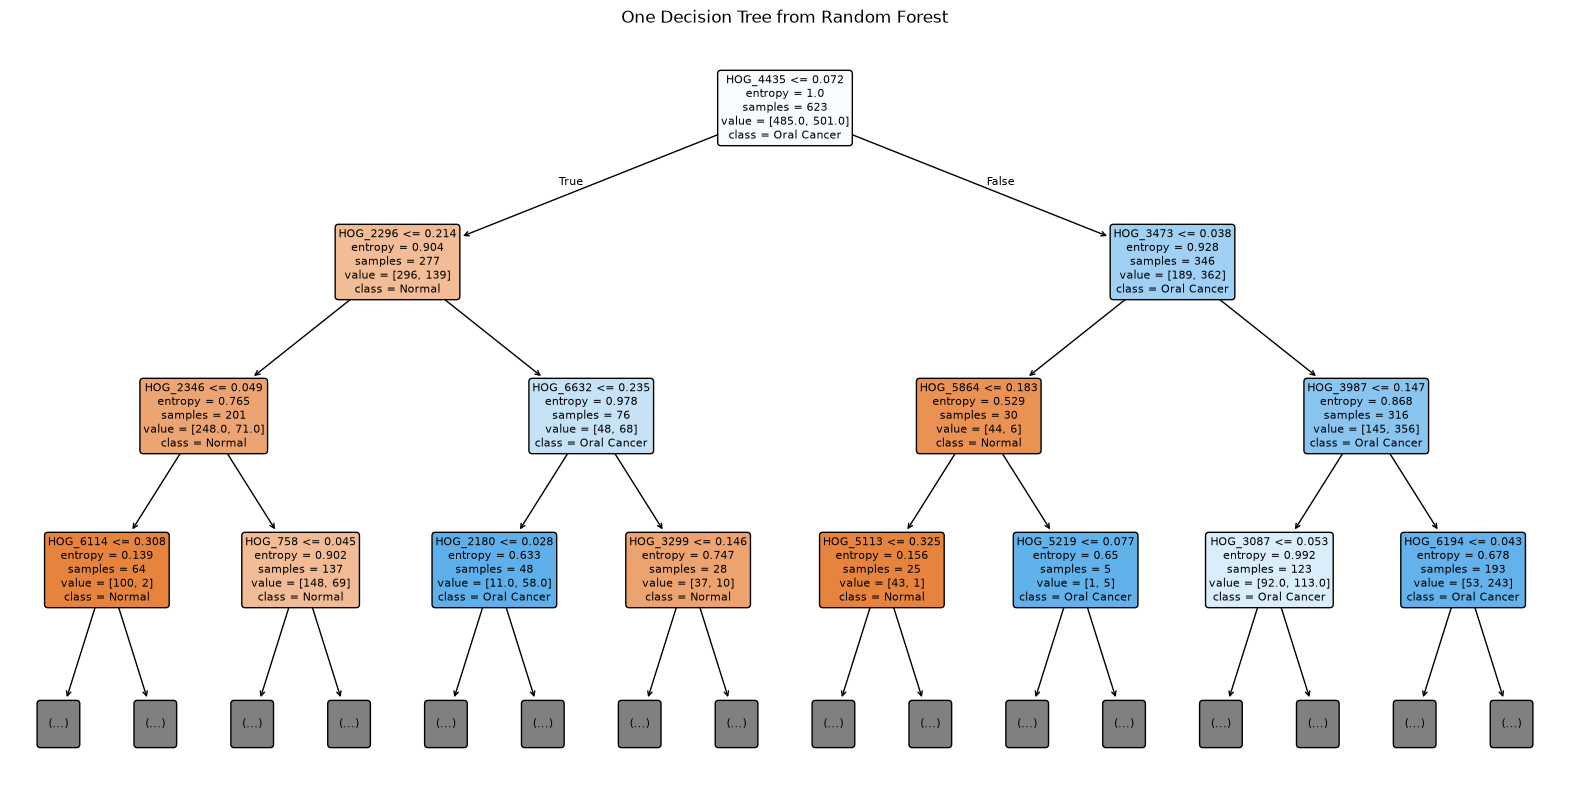

In [20]:
rf_model = grid_random_forest.best_estimator_[0]

plt.figure(figsize=(20, 10))
plot_tree(
    rf_model.estimators_[0],
    max_depth=3,
    filled=True,
    feature_names=[f"HOG_{i}" for i in range(X_Train.shape[1])],
    class_names=["Normal", "Oral Cancer"],
    rounded=True,
    fontsize=8
)
plt.title("One Decision Tree from Random Forest")
plt.show()

#XGBoost

In [ ]:
clf_XGB = XGBClassifier(
                        reg_alpha=0.1,
                        reg_lambda=5,
                        subsample=0.8,
                        colsample_bytree=0.8,
                        random_state=42,
                        eval_metric="logloss",
                        n_jobs=1
)

pipeline_XGB = Pipeline([
    ("model", clf_XGB)
])

param_XGB = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8],
    "model__colsample_bytree": [0.8],
    "model__reg_alpha": [0.1],
    "model__reg_lambda": [5]
}


grid_XGB = GridSearchCV(
    pipeline_XGB,
    param_XGB,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=10
)

grid_XGB.fit(X_Train, y_Train)

y_pred_test = grid_XGB.predict(X_Test)

best_estimator = grid_XGB.best_estimator_
best_param = grid_XGB.best_params_
best_score = grid_XGB.best_score_

print(f"Best Estimator:\n{best_estimator}")
print(f"\nBest Parameters:\n{best_param}")
print(f"\nBest CV Score: {best_score:.4f}")

acc_score = accuracy_score(y_Test, y_pred_test)

clf_report = classification_report(
    y_Test,
    y_pred_test,
    target_names=["Normal", "Oral Cancer"]
)

cm_XGB = confusion_matrix(y_Test, y_pred_test)

print(f"XGBoost ،Accuracy: {acc_score:.4f}")

print(f"Classification Report: {clf_report}")

print(f"confusion_matrix: {cm_XGB}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Estimator:
Pipeline(steps=[('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.8, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan

##Confusion matrix for XGBoost

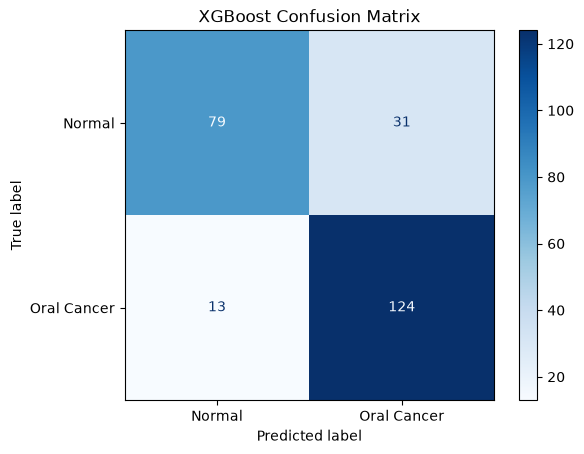

In [11]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_XGB,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("XGBoost Confusion Matrix")
plt.show()
plt.show()

##Feature importance for XGBoost

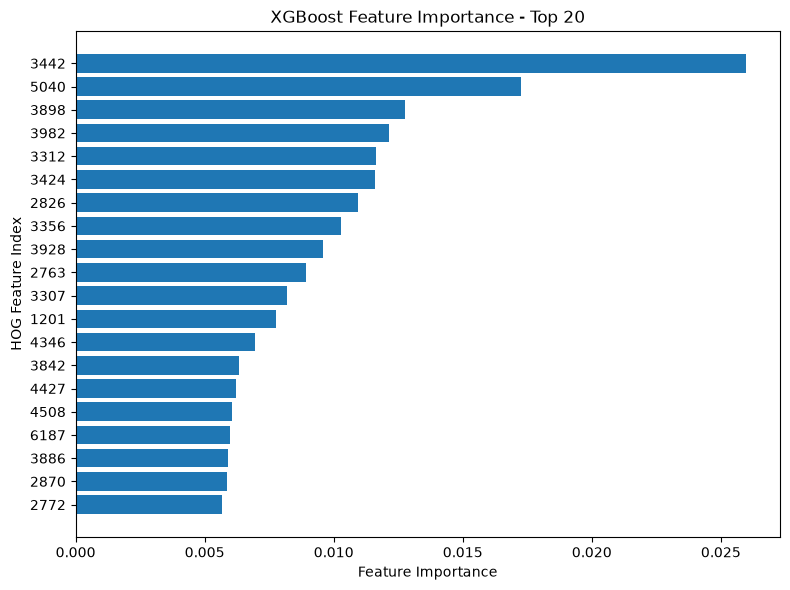

In [12]:
XGB_model = grid_XGB.best_estimator_.named_steps["model"]
importances = XGB_model.feature_importances_

indices = np.argsort(importances)[-20:]

plt.figure(figsize=(8, 6))

plt.barh(
    range(len(indices)),
    importances[indices]
)

plt.yticks(
    range(len(indices)),
    indices
)

plt.xlabel("Feature Importance")
plt.ylabel("HOG Feature Index")
plt.title("XGBoost Feature Importance - Top 20")

plt.tight_layout()
plt.show()

##ROC for XGBoost

XGBoost ROC-AUC: 0.8630


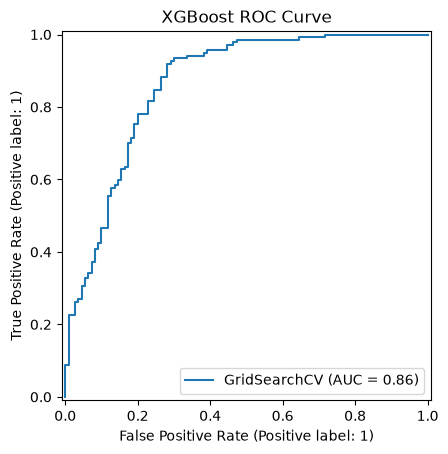

In [13]:
best_xgb = grid_XGB.best_estimator_
y_score_xgb = best_xgb.predict_proba(X_Test)[:, 1]
auc_xgb = roc_auc_score(y_Test, y_score_xgb)

RocCurveDisplay.from_estimator(
    grid_XGB,
    X_Test,
    y_Test
)
print(f"XGBoost ROC-AUC: {auc_xgb:.4f}")
plt.title("XGBoost ROC Curve")
plt.show()

##Precision for XGBoost

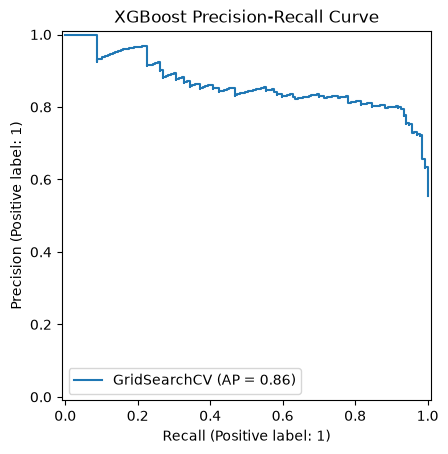

In [14]:
PrecisionRecallDisplay.from_estimator(
    grid_XGB,
    X_Test,
    y_Test
)

plt.title("XGBoost Precision-Recall Curve")
plt.show()

XGBoost ROC-AUC: 0.8630


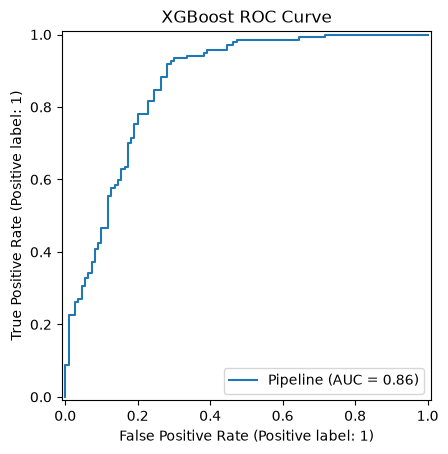

In [15]:
best_xgb = grid_XGB.best_estimator_

y_score_xgb = best_xgb.predict_proba(X_Test)[:, 1]

auc_xgb = roc_auc_score(y_Test, y_score_xgb)
print(f"XGBoost ROC-AUC: {auc_xgb:.4f}")

RocCurveDisplay.from_estimator(
    best_xgb,
    X_Test,
    y_Test
)

plt.title("XGBoost ROC Curve")
plt.show()

#SVM

In [16]:
model = SVC(
    class_weight="balanced",
    probability= True,
    random_state=42
)

pipeline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", model)
])

param_SVM = {
    "model__kernel": ["linear", "rbf"],
    "model__C": [0.1, 1],
    "model__gamma": ["scale", 0.01]
}
#param_SVM = {
#   "model__kernel": ["linear", "poly", "rbf"],
#    "model__C": [0.1, 1, 3, 6, 10],
#    "model__gamma": ["scale", 0.1, 1, 3, 6, 10],
#}

grid_SVM = GridSearchCV(
    pipeline_svm,
    param_SVM,
    cv=cv,
    scoring = {
                 "accuracy": "accuracy",
                 "f1_macro": "f1_macro",
                 "precision": "precision",
                 "recall": "recall"
},
    refit="f1_macro",
    n_jobs=-1,
    verbose=2
)

grid_SVM.fit(X_Train, y_Train)

y_pred_test = grid_SVM.predict(X_Test)

best_estimator = grid_SVM.best_estimator_
best_param = grid_SVM.best_params_
best_score = grid_SVM.best_score_

print(f"Best Estimator:\n{best_estimator}")
print(f"Best Parameters:\n{best_param}")
print(f"Best CV Score: {best_score:.4f}")

acc_score = accuracy_score(y_Test, y_pred_test)

clf_report = classification_report(
    y_Test,
    y_pred_test,
    target_names=["Normal", "Oral Cancer"]
)

cm_SVM = confusion_matrix(y_Test, y_pred_test)

print(f"SVM Test Accuracy: {acc_score:.4f}")
print(f"Classification Report:\n{clf_report}")
print(f"confusion_matrix: {cm_SVM}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits


c:\Users\MY HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best Estimator:
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 SVC(C=1, class_weight='balanced', probability=True,
                     random_state=42))])
Best Parameters:
{'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV Score: 0.8314
SVM Test Accuracy: 0.8340
Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.72      0.79       110
 Oral Cancer       0.80      0.93      0.86       137

    accuracy                           0.83       247
   macro avg       0.85      0.82      0.83       247
weighted avg       0.84      0.83      0.83       247

confusion_matrix: [[ 79  31]
 [ 10 127]]


##confusion matrix for SVM

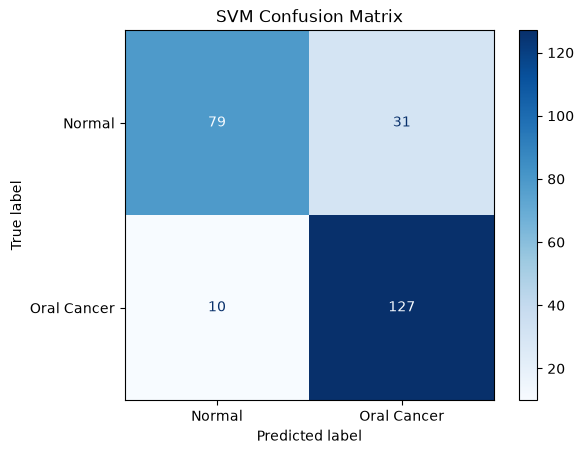

In [17]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_SVM,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("SVM Confusion Matrix")
plt.show()
plt.show()

##ROC for SVM

SVM ROC-AUC: 0.8554


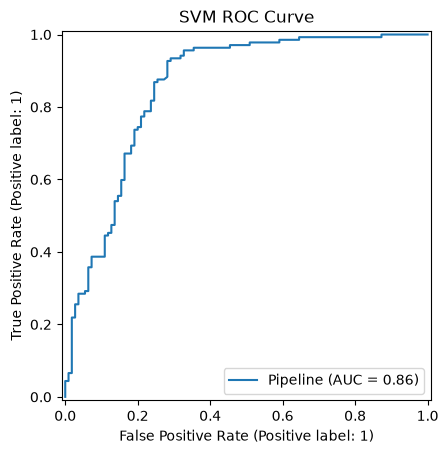

In [18]:
best_SVM = grid_SVM.best_estimator_

y_score_SVM = best_SVM.decision_function(X_Test)

auc_SVM = roc_auc_score(y_Test, y_score_SVM)

print(f"SVM ROC-AUC: {auc_SVM:.4f}")

RocCurveDisplay.from_estimator(
    best_SVM,
    X_Test,
    y_Test
)

plt.title("SVM ROC Curve")
plt.show()

##Precision for SVM

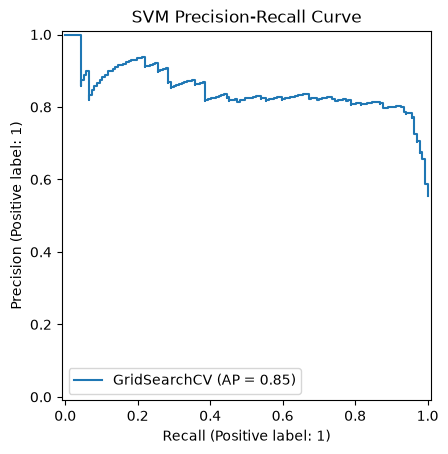

In [19]:
PrecisionRecallDisplay.from_estimator(
    grid_SVM,
    X_Test,
    y_Test
)

plt.title("SVM Precision-Recall Curve")
plt.show()

#Logistic Regression

In [32]:
pipeline_LR = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        class_weight="balanced",
        random_state=42
    ))
])

param_LR = [
    {
        "model__penalty": ["l1", "l2"],
        "model__C": [0.1, 1, 10],
        "model__tol": [1e-3],
        "model__max_iter": [1000]
    },
    {
        "model__penalty": ["elasticnet"],
        "model__C": [ 0.1, 1, 10],
        "model__l1_ratio": [0.25, 0.5, 0.75],
        "model__tol": [1e-3],
        "model__max_iter": [1000]
    }
]

grid_LR = GridSearchCV(
    estimator=pipeline_LR,
    param_grid=param_LR,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_LR.fit(X_Train, y_Train)

best_LR = grid_LR.best_estimator_

print("Best Parameters:", grid_LR.best_params_)
print(f"Best CV F1-macro: {grid_LR.best_score_:.4f}")

y_pred_LR = best_LR.predict(X_Test)

print(f"LR Test Accuracy: {accuracy_score(y_Test, y_pred_LR):.4f}")

print(classification_report(
    y_Test,
    y_pred_LR,
    target_names=["Normal", "Oral Cancer"]
))

cm_LR = confusion_matrix(y_Test, y_pred_LR)
print("Confusion Matrix:", cm_LR)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


c:\Users\MY HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best Parameters: {'model__C': 0.1, 'model__l1_ratio': 0.75, 'model__max_iter': 1000, 'model__penalty': 'elasticnet', 'model__tol': 0.001}
Best CV F1-macro: 0.8123
LR Test Accuracy: 0.7854
              precision    recall  f1-score   support

      Normal       0.77      0.75      0.76       110
 Oral Cancer       0.80      0.82      0.81       137

    accuracy                           0.79       247
   macro avg       0.78      0.78      0.78       247
weighted avg       0.79      0.79      0.79       247

Confusion Matrix: [[ 82  28]
 [ 25 112]]


##Confusion for Logistic regresiion

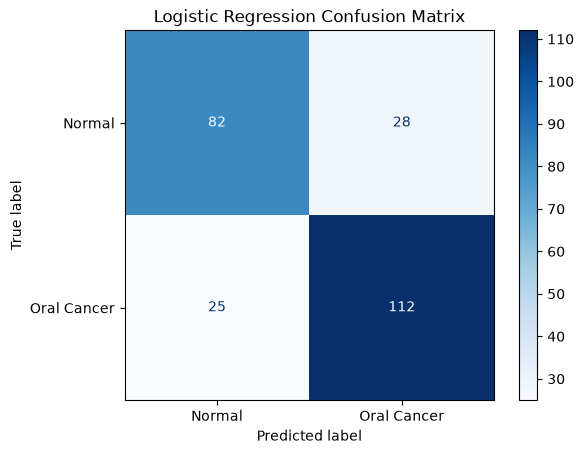

In [33]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_LR,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()
plt.show()

##ROC for Logistic regresiion

Logistic Regression ROC-AUC: 0.8301260783012607


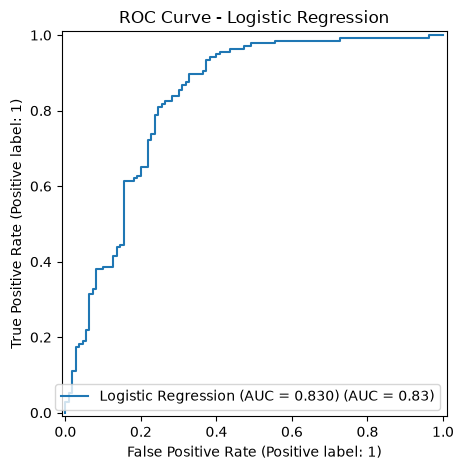

In [34]:
y_score_LR = best_LR.predict_proba(X_Test)[:, 1]

auc_LR = roc_auc_score(y_Test, y_score_LR)
print("Logistic Regression ROC-AUC:", auc_LR)

RocCurveDisplay.from_predictions(
    y_Test,
    y_score_LR,
    name=f"Logistic Regression (AUC = {auc_LR:.3f})"
)

plt.title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.show()

##PrecisionRecall for Logistic Regression

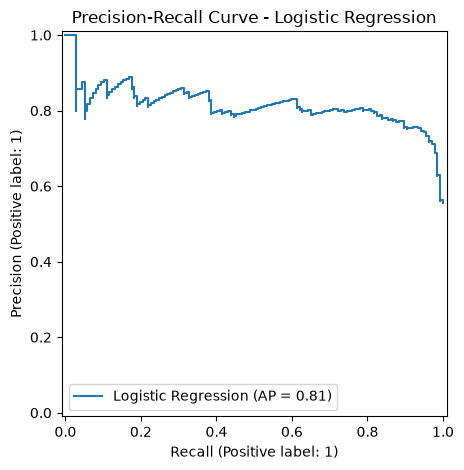

In [35]:
PrecisionRecallDisplay.from_predictions(
    y_Test,
    y_score_LR,
    name="Logistic Regression"
)

plt.title("Precision-Recall Curve - Logistic Regression")
plt.tight_layout()
plt.show()

#MLP

In [20]:
pipeline_MLP = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        max_iter=5000,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42
    ))
])

param_MLP = {
    "model__hidden_layer_sizes": [
                (256 , 128, 64),
                (256 , 128 , 64, 32 , 16 , 8 , 4 , 2 ),
                (256, 256 , 128, 64, 32 , 16 , 8  , 4 , 2)
                
                                  ],
    "model__activation": ["relu"],
    "model__alpha": [0.001]
}

grid_MLP = GridSearchCV(
    estimator=pipeline_MLP,
    param_grid=param_MLP,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_MLP.fit(X_Train, y_Train)
best_MLP = grid_MLP.best_estimator_
y_pred_MLP = best_MLP.predict(X_Test)


print(classification_report(y_Test,y_pred_MLP,target_names=["Normal", "Oral Cancer"]))
cm_MLP = confusion_matrix(y_Test, y_pred_MLP)

print("Best Parameters:", grid_MLP.best_params_)
print("Best CV F1-macro:", grid_MLP.best_score_)
print("Confusion Matrix:", cm_MLP)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
              precision    recall  f1-score   support

      Normal       0.84      0.69      0.76       110
 Oral Cancer       0.78      0.89      0.83       137

    accuracy                           0.80       247
   macro avg       0.81      0.79      0.79       247
weighted avg       0.81      0.80      0.80       247

Best Parameters: {'model__activation': 'relu', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (256, 256, 128, 64, 32, 16, 8, 4, 2)}
Best CV F1-macro: 0.8297856223351563
Confusion Matrix: [[ 76  34]
 [ 15 122]]


##confusion matrix for MLP

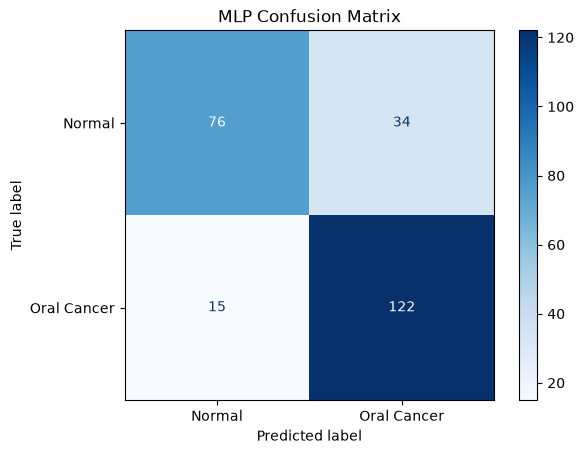

In [21]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_MLP,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("MLP Confusion Matrix")
plt.show()
plt.show()

##ROC for MLP

MLP ROC-AUC: 0.8238885202388851


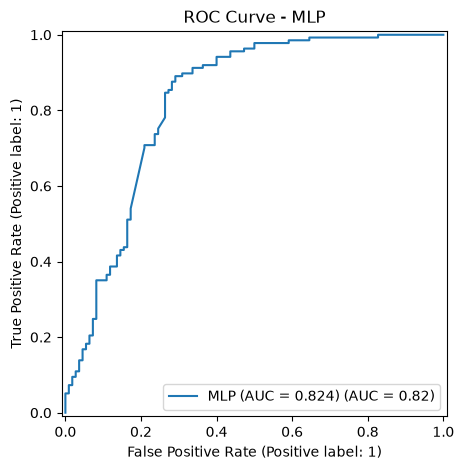

In [22]:
y_score_MLP = best_MLP.predict_proba(X_Test)[:, 1]

auc_MLP = roc_auc_score(y_Test, y_score_MLP)
print("MLP ROC-AUC:", auc_MLP)

RocCurveDisplay.from_predictions(
    y_Test,
    y_score_MLP,
    name=f"MLP (AUC = {auc_MLP:.3f})"
)

plt.title("ROC Curve - MLP")
plt.tight_layout()
plt.show()

##PrecisionRecall for MLP

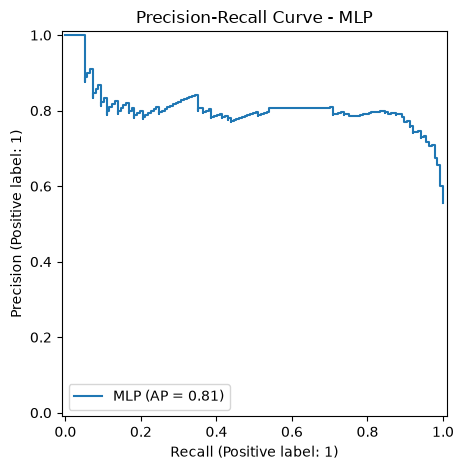

In [23]:
PrecisionRecallDisplay.from_predictions(
    y_Test,
    y_score_MLP,
    name="MLP"
)

plt.title("Precision-Recall Curve - MLP")
plt.tight_layout()
plt.show()

#Ensemble Learning

In [40]:

svm_best = grid_SVM.best_estimator_
xgb_best = grid_XGB.best_estimator_

voting_model = VotingClassifier(
    estimators=[
        ("svm", svm_best),
        ("xgb", xgb_best)
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=-1
)

voting_model.fit(X_Train, y_Train)

y_pred = voting_model.predict(X_Test)
y_prob = voting_model.predict_proba(X_Test)[:, 1]

print("Accuracy:", accuracy_score(y_Test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_Test, y_pred))
print("\nConfusion Matrix:\n",
      confusion_matrix(y_Test, y_pred))
print("ROC-AUC:", roc_auc_score(y_Test, y_prob))

Accuracy: 0.8178137651821862

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.74      0.78       110
           1       0.81      0.88      0.84       137

    accuracy                           0.82       247
   macro avg       0.82      0.81      0.81       247
weighted avg       0.82      0.82      0.82       247


Confusion Matrix:
 [[ 81  29]
 [ 16 121]]
ROC-AUC: 0.8631718646317187


##confusion matrix for Votting SVM and XGB

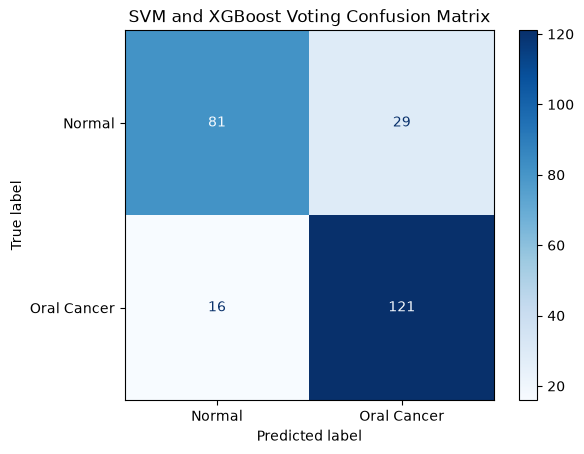

In [ ]:
cm_voting = confusion_matrix(y_Test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_voting,
    display_labels=["Normal", "Oral Cancer"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("SVM and XGBoost Voting Confusion Matrix")
plt.show()

##ROC for Votting SVM and XGB

voting ROC-AUC: 0.8674187126741871


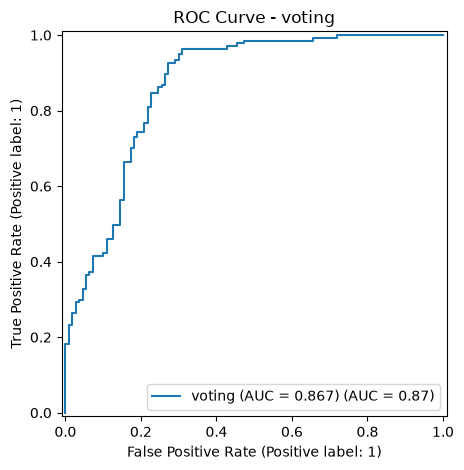

In [52]:
y_score_voting = voting_model.predict_proba(X_Test)[:, 1]

auc_voting = roc_auc_score(y_Test, y_score_voting)
print("voting ROC-AUC:", auc_voting)

RocCurveDisplay.from_predictions(
    y_Test,
    y_score_voting,
    name=f"voting (AUC = {auc_voting:.3f})"
)

plt.title("ROC Curve - voting")
plt.tight_layout()
plt.show()

##Precision for Votting SVM and XGB

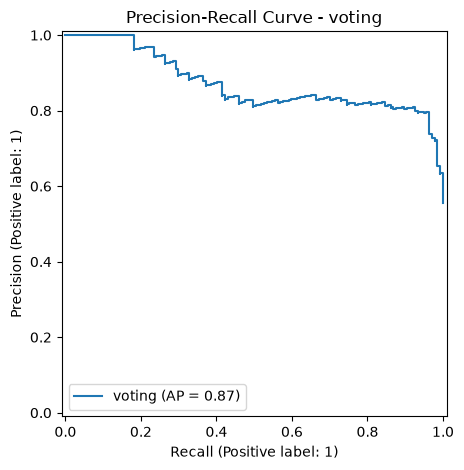

In [45]:
PrecisionRecallDisplay.from_predictions(
    y_Test,
    y_score_voting,
    name="voting"
)

plt.title("Precision-Recall Curve - voting")
plt.tight_layout()
plt.show()

#Votting with 3 models

In [ ]:
svm_best = grid_SVM.best_estimator_
xgb_best = grid_XGB.best_estimator_
MLP_best = grid_MLP.best_estimator_

voting_model = VotingClassifier(
    estimators=[
        ("svm", svm_best),
        ("xgb", xgb_best),
        ("rf", MLP_best)
    ],
    voting="soft",
    weights=[1, 1, 1],
    n_jobs=-1
)

voting_model.fit(X_Train, y_Train)

y_pred = voting_model.predict(X_Test)
y_prob = voting_model.predict_proba(X_Test)[:, 1]

print("Accuracy:", accuracy_score(y_Test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_Test, y_pred))
print("\nConfusion Matrix:\n",
      confusion_matrix(y_Test, y_pred))
print("ROC-AUC:", roc_auc_score(y_Test, y_prob))

Accuracy: 0.8259109311740891

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.74      0.79       110
           1       0.81      0.90      0.85       137

    accuracy                           0.83       247
   macro avg       0.83      0.82      0.82       247
weighted avg       0.83      0.83      0.82       247


Confusion Matrix:
 [[ 81  29]
 [ 14 123]]
ROC-AUC: 0.86264100862641


##confusion matrix for Votting SVM and XGB and MLP

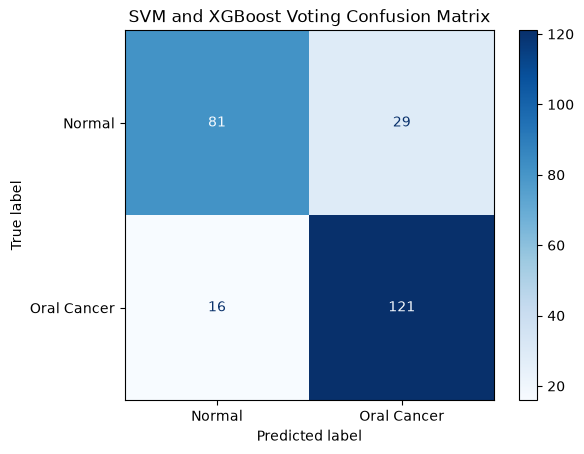

In [ ]:
cm_voting = confusion_matrix(y_Test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_voting,
    display_labels=["Normal", "Oral Cancer"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("SVM and XGBoost and MLP Voting Confusion Matrix")
plt.show()

##ROC for Votting SVM and XGB and MLP

voting ROC-AUC: 0.8674187126741871


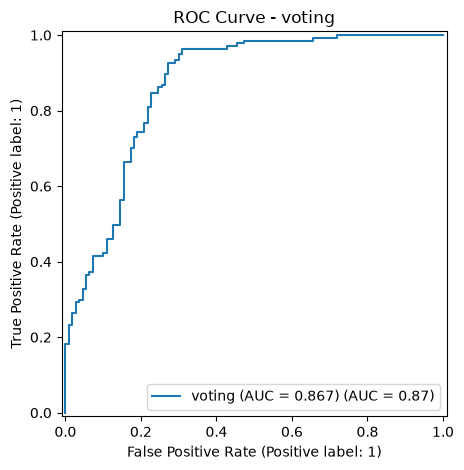

In [50]:
y_score_voting = voting_model.predict_proba(X_Test)[:, 1]

auc_voting = roc_auc_score(y_Test, y_score_voting)
print("voting ROC-AUC:", auc_voting)

RocCurveDisplay.from_predictions(
    y_Test,
    y_score_voting,
    name=f"voting (AUC = {auc_voting:.3f})"
)

plt.title("ROC Curve - voting")
plt.tight_layout()
plt.show()

##Precision for Votting SVM and XGB and MLP

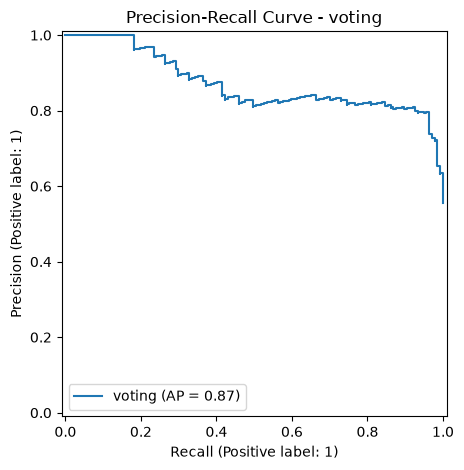

In [51]:
PrecisionRecallDisplay.from_predictions(
    y_Test,
    y_score_voting,
    name="voting"
)

plt.title("Precision-Recall Curve - voting")
plt.tight_layout()
plt.show()

#3 models

In [56]:

svm_best = grid_SVM.best_estimator_
xgb_best = grid_XGB.best_estimator_
RandomForest_best = grid_random_forest.best_estimator_

voting_model = VotingClassifier(
    estimators=[
        ("svm", svm_best),
        ("xgb", xgb_best),
        ("rf", RandomForest_best)
    ],
    voting="soft",
    weights=[1, 1, 1],
    n_jobs=-1
)

voting_model.fit(X_Train, y_Train)

y_pred = voting_model.predict(X_Test)
y_prob = voting_model.predict_proba(X_Test)[:, 1]

print("Accuracy:", accuracy_score(y_Test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_Test, y_pred))
print("\nConfusion Matrix:\n",
      confusion_matrix(y_Test, y_pred))
print("ROC-AUC:", roc_auc_score(y_Test, y_prob))

Accuracy: 0.8178137651821862

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.74      0.78       110
           1       0.81      0.88      0.84       137

    accuracy                           0.82       247
   macro avg       0.82      0.81      0.81       247
weighted avg       0.82      0.82      0.82       247


Confusion Matrix:
 [[ 81  29]
 [ 16 121]]
ROC-AUC: 0.8674187126741871


##confusion matrix for Votting SVM and XGB and Randomforest

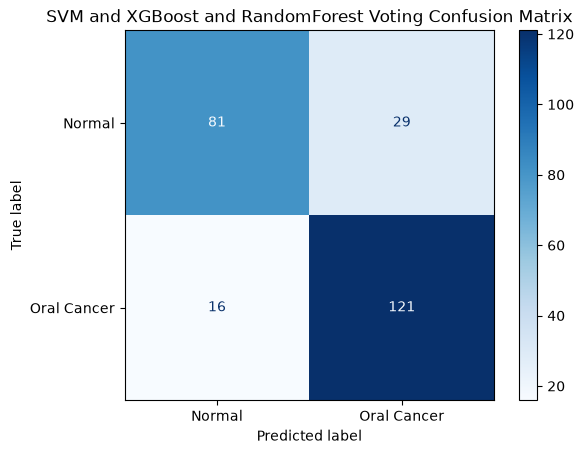

In [57]:
cm_voting = confusion_matrix(y_Test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_voting,
    display_labels=["Normal", "Oral Cancer"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("SVM and XGBoost and RandomForest Voting Confusion Matrix")
plt.show()

##ROC for Votting SVM and XGB and RandomForest

voting ROC-AUC: 0.8674187126741871


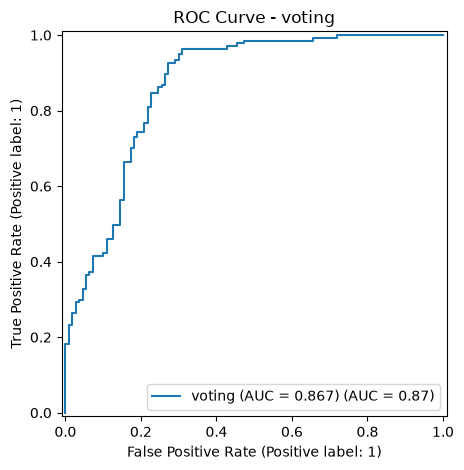

In [58]:
y_score_voting = voting_model.predict_proba(X_Test)[:, 1]

auc_voting = roc_auc_score(y_Test, y_score_voting)
print("voting ROC-AUC:", auc_voting)

RocCurveDisplay.from_predictions(
    y_Test,
    y_score_voting,
    name=f"voting (AUC = {auc_voting:.3f})"
)

plt.title("ROC Curve - voting")
plt.tight_layout()
plt.show()

##Precision for Votting SVM and XGB and RandomForest

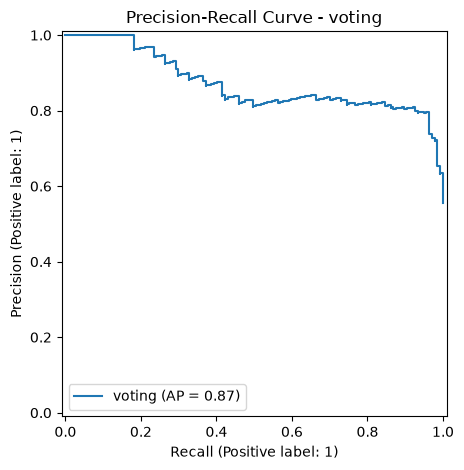

In [59]:
PrecisionRecallDisplay.from_predictions(
    y_Test,
    y_score_voting,
    name="voting"
)

plt.title("Precision-Recall Curve - voting")
plt.tight_layout()
plt.show()

#changing weights in voting

In [24]:
svm_best = grid_SVM.best_estimator_
xgb_best = grid_XGB.best_estimator_
mlp_best = grid_MLP.best_estimator_

weight_options = [
    [1, 1, 1],
    [2, 1, 1],
    [1, 2, 1],
    [1, 1, 2],
    [2, 2, 1],
    [2, 1, 2],
    [1, 2, 2]
]

results = []

for weights in weight_options:

    voting_model = VotingClassifier(
        estimators=[
            ("svm", svm_best),
            ("xgb", xgb_best),
            ("mlp", mlp_best)
        ],
        voting="soft",
        weights=weights,
        n_jobs=-1
    )

    scores = cross_val_score(
        voting_model,
        X_Train,
        y_Train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1
    )

    results.append({
        "weights": weights,
        "mean_f1_macro": scores.mean(),
        "std_f1_macro": scores.std()
    })

for result in sorted(
    results,
    key=lambda x: x["mean_f1_macro"],
    reverse=True
):
    print(result)

{'weights': [2, 1, 1], 'mean_f1_macro': np.float64(0.8339610085697364), 'std_f1_macro': np.float64(0.028966173617203436)}
{'weights': [1, 2, 2], 'mean_f1_macro': np.float64(0.8338755830764629), 'std_f1_macro': np.float64(0.02564316294780848)}
{'weights': [2, 2, 1], 'mean_f1_macro': np.float64(0.8326432370284118), 'std_f1_macro': np.float64(0.03041911010996517)}
{'weights': [1, 1, 1], 'mean_f1_macro': np.float64(0.8320126094797894), 'std_f1_macro': np.float64(0.026046022813228528)}
{'weights': [1, 2, 1], 'mean_f1_macro': np.float64(0.8306709350005794), 'std_f1_macro': np.float64(0.03025942828289269)}
{'weights': [1, 1, 2], 'mean_f1_macro': np.float64(0.8299392149191025), 'std_f1_macro': np.float64(0.02242566150147492)}
{'weights': [2, 1, 2], 'mean_f1_macro': np.float64(0.8288976685551038), 'std_f1_macro': np.float64(0.02549567880838496)}


In [ ]:
svm_best = grid_SVM.best_estimator_
xgb_best = grid_XGB.best_estimator_
MLP_best = grid_MLP.best_estimator_

voting_final = VotingClassifier(
    estimators=[
        ("svm", svm_best),
        ("xgb", xgb_best),
        ("mlp", MLP_best)
    ],
    voting="soft",
    weights=[2, 1, 1],
    n_jobs=-1
)

voting_final.fit(X_Train, y_Train)

y_pred_final = voting_final.predict(X_Test)
y_prob_final = voting_final.predict_proba(X_Test)[:, 1]

acc_score = accuracy_score(y_Test, y_pred_final)
clf_report = classification_report(y_Test, y_pred_final)
cm_voting = confusion_matrix(y_Test, y_pred_final)

print(f"Accuracy:{acc_score}")
print(f"Classification Report:{clf_report}")     
print(f"Confusion Matrix: {cm_voting}")
print("ROC-AUC:", roc_auc_score(y_Test, y_prob_final))

Accuracy: 0.8340080971659919

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.74      0.80       110
           1       0.81      0.91      0.86       137

    accuracy                           0.83       247
   macro avg       0.84      0.82      0.83       247
weighted avg       0.84      0.83      0.83       247


Confusion Matrix:
 [[ 81  29]
 [ 12 125]]
ROC-AUC: 0.861579296615793


##confusion matrix for final voting

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix= cm_voting,
                              display_labels=["Normal", "Oral Cancer"])

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("final voting Confusion Matrix")
plt.show()
plt.show()

##ROC for  final votting

In [ ]:
y_score_voting_final = voting_final.predict_proba(X_Test)[:, 1]

auc_voting_fianl = roc_auc_score(y_Test, y_score_MLP)

print(f"final voting ROC-AUC: {auc_voting_fianl:.4f}")

RocCurveDisplay.from_estimator( voting_final , X_Test , y_Test)

plt.title("voting_final ROC Curve")
plt.show()

##PrecisionRecall for final voting

In [ ]:
PrecisionRecallDisplay.from_estimator(voting_final, X_Test, y_Test)

plt.title("final voting Precision-Recall Curve")
plt.show()